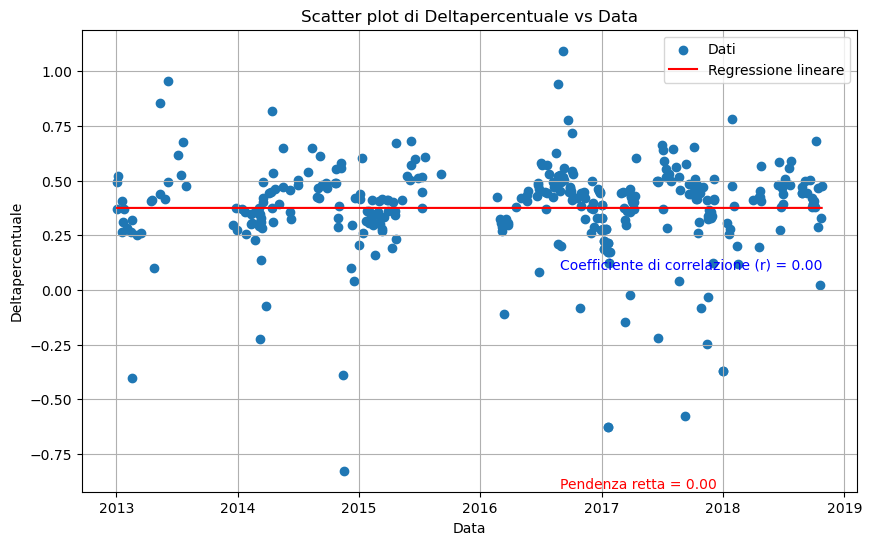

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sqlite3

# Connessione al database SQLite
conn = sqlite3.connect(r'C:\Users\vitto\Desktop\VB\UNIVERSITÀ\STAGE\RADIAZIONE\DETERIORAMENTO_DATO\STAZIONE83\83_ORARIA.db')
cursor = conn.cursor()

# Query per selezionare i dati dalla prima colonna desiderata della tabella
query_colonna1 = "SELECT data FROM clearsky_h_13"
cursor.execute(query_colonna1)
x = cursor.fetchall()

# Query per selezionare i dati dalla seconda colonna desiderata della tabella
query_colonna2 = "SELECT deltapercentuale FROM clearsky_h_13"
cursor.execute(query_colonna2)
y = cursor.fetchall()

# Chiusura della connessione al database
conn.close()

# Converti le liste di tuple in array NumPy
# Converti le date da tuple a stringhe
x = [date[0] for date in x]

# Converti le date in oggetti datetime
x = pd.to_datetime(x, format='%d/%m/%Y')  # Specifica il formato della data 'YYYY-MM-DD'

# Converti la seconda colonna in array NumPy di float
y = np.array([float(val[0]) for val in y])

# Converti le date in numeri (numero di giorni dal primo giorno)
x_numeric = (x - x.min()).days

# Calcolo della retta di regressione lineare
slope, intercept = np.polyfit(x_numeric, y, 1)
line = slope * x_numeric + intercept

# Calcolo del coefficiente di correlazione lineare (r)
r = np.corrcoef(x_numeric, y)[0, 1]

# Creazione del grafico
plt.figure(figsize=(10, 6))
plt.scatter(x, y, label='Dati')
plt.plot(x, line, color='red', label='Regressione lineare')

# Aggiunta del coefficiente di correlazione lineare (r) come testo nel grafico
midpoint = len(x) // 2
plt.text(x[midpoint], max(y) - 1, f'Coefficiente di correlazione (r) = {r:.2f}', fontsize=10, color='blue')
plt.text(x[midpoint], max(y) - 2, f'Pendenza retta = {slope:.2f}', fontsize=10, color='red')

plt.xlabel('Data')
plt.ylabel('Deltapercentuale')
plt.title('Scatter plot di Deltapercentuale vs Data')
plt.legend()
plt.grid(True)
plt.show()
